# Jev vs two OpenRouter LLMs on the UCI Maternal Health Risk labels - results notebook

This notebook is **offline**: it reads only the sanitized, non-secret committed
artifacts under `published/` (see `published/MANIFEST.json`) and makes **no paid
API request and no network call of any kind**. Every figure below comes from the
one completed real experiment, run `run-20261006T142452Z` (1,014 official UCI rows
x 3 providers = 3,042 row-provider pairs).

The notebook intentionally recomputes the published README numbers from the raw
artifacts and asserts they match an independent recount, so the tables below and
the README cannot silently drift apart.

> Retrospective replication of existing public dataset labels. Not a clinical
> tool; no diagnosis, triage, treatment, or patient-safety claim. No calibration
> or clinical-validity claim is made from the exploratory probability sections.

In [1]:
import json
from itertools import combinations
from pathlib import Path

import pandas as pd

from jev_benchmark import figures as figures_mod
from jev_benchmark import metrics, spec
from jev_benchmark import report as report_mod
from jev_benchmark.dataset import prepare_dataset
from jev_benchmark.runner import CaseRecord


# Resolve the repository root from the kernel working directory (the notebook
# may be executed from the repo root or from notebooks/).
def find_repo_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "published" / "cases.jsonl").is_file():
            return candidate
    raise FileNotFoundError(
        "cannot locate published/cases.jsonl from the current working directory; "
        "this notebook reproduces results only from a checkout that contains the "
        "committed published/ artifacts"
    )

ROOT = find_repo_root()
PUBLISHED = ROOT / "published"

required = ["run.json", "cases.jsonl", "stages.jsonl", "shared_budget.json", "MANIFEST.json"]
missing = [name for name in required if not (PUBLISHED / name).is_file()]
if missing:
    raise FileNotFoundError(
        f"published artifacts incomplete; missing {missing}. Clone the repository "
        "fully (the published/ directory is committed) before running this notebook."
    )

run_state = json.loads((PUBLISHED / "run.json").read_text())
manifest = json.loads((PUBLISHED / "MANIFEST.json").read_text())
cases = [CaseRecord.from_dict(json.loads(line))
         for line in (PUBLISHED / "cases.jsonl").read_text().splitlines() if line.strip()]
stage_entries = [json.loads(line)
                 for line in (PUBLISHED / "stages.jsonl").read_text().splitlines() if line.strip()]
shared_budget = json.loads((PUBLISHED / "shared_budget.json").read_text())

print(f"run id              : {run_state['run_id']}")
print(
    f"status              : {run_state['status']} "
    f"({len(cases)}/{run_state['planned_pairs']} row-provider pairs)"
)
print(f"models              : {run_state['model_ids']}")
print(f"config hash         : {run_state['config_hash']}")
print(f"ordered-record hash : {run_state['ordered_record_sha256']}")
print(f"created / updated   : {run_state['created_at']} / {run_state['updated_at']}")
print(
    f"active dispatch time : {run_state['total_run_seconds']:.1f}s "
    "(cumulative active dispatch; monotonic client clock, idle time excluded)"
)
print(
    f"artifact manifest   : {len(manifest['files'])} files, "
    "sha256 recorded in published/MANIFEST.json"
)

run id              : run-20261006T142452Z
status              : complete (3042/3042 row-provider pairs)
models              : ['jev-1.13.0', 'openai/gpt-4o-mini', 'google/gemini-2.5-flash']
config hash         : 6c7bab9c0fee0d1f35bc47e32caafafeb238890c17ee74e25c107b3f426f3440
ordered-record hash : ea285a63e5a4c16a5cfa8622db164edd932dc97046dff455b70ba784b43dcffe
created / updated   : 2026-10-06T14:24:52Z / 2026-10-08T14:53:38Z
active dispatch time : 5396.4s (cumulative active dispatch; monotonic client clock, idle time excluded)
artifact manifest   : 5 files, sha256 recorded in published/MANIFEST.json


## Dataset identity and known anomalies

The official UCI Maternal Health Risk CSV (dataset 863, CC BY 4.0) is committed
at `data/raw/maternal_health_risk.csv`; the notebook re-derives its ordered-record
hash and checks it equals the hash frozen into the run header, proving the run
and this checkout describe the same data in the same order. Known anomalies are
stated, not hidden: the served CSV has **1,014 rows** while UCI's metadata
reports **1,013 instances** (no row is dropped); there are **452 distinct
complete rows** and **35 feature-vector groups with conflicting labels**.

In [2]:
dataset = prepare_dataset(source=ROOT / "data" / "raw" / "maternal_health_risk.csv")
if dataset.provenance["ordered_record_sha256"] != run_state["ordered_record_sha256"]:
    raise ValueError("dataset identity mismatch between local CSV and the published run")
if dataset.provenance["config_hash"] != run_state["config_hash"]:
    raise ValueError("frozen task identity mismatch between local code and the published run")
if dataset.provenance["row_count"] != 1014:
    raise ValueError("expected the official 1,014-row population")

audit = dataset.audit
print(
    f"rows kept              : {audit['total_rows']} "
    "(UCI metadata reports 1,013; discrepancy documented, nothing dropped)"
)
print(f"class distribution     : {dataset.provenance['class_distribution']}")
print(f"distinct complete rows : {audit['distinct_complete_rows']}")
print(
    f"distinct feature vectors: {audit['distinct_feature_vectors']} "
    f"({audit['conflicting_label_groups']} conflicting-label groups)"
)
print(
    "duplicates remain in the primary population; deduplication appears "
    "only in the sensitivity section below"
)

rows kept              : 1014 (UCI metadata reports 1,013; discrepancy documented, nothing dropped)
class distribution     : {'high risk': 272, 'mid risk': 336, 'low risk': 406}
distinct complete rows : 452
distinct feature vectors: 416 (35 conflicting-label groups)
duplicates remain in the primary population; deduplication appears only in the sensitivity section below


## Coverage (attempted population)

Every one of the 3,042 planned pairs was attempted. `invalid/abstained` groups
invalid and refused outcomes (a returned response that could not become a
label); `failed` groups identity-mismatch and transport-error outcomes. Nothing
was silently dropped.

In [3]:
cov_rows = []
for model in spec.MODEL_IDS:
    cov = metrics.coverage_counts(cases, model, planned_rows=len(run_state["planned_row_indices"]))
    cov_rows.append({"provider": model, **cov})
coverage_df = pd.DataFrame(cov_rows).set_index("provider")
display(coverage_df[["attempted", "predicted", "invalid_or_abstained", "failed", "unattempted"]])

# Reconciliation guard: attempted must decompose exactly into its outcome parts.
for model in spec.MODEL_IDS:
    cov = coverage_df.loc[model]
    assert cov["attempted"] == (cov["predicted"] + cov["invalid_or_abstained"] + cov["failed"])
    assert cov["attempted"] == 1014 and cov["unattempted"] == 0
print("coverage reconciliation checks passed for all three providers")

,attempted,predicted,invalid_or_abstained,failed,unattempted
provider,,,,,
jev-1.13.0,1014,1014,0,0,0
openai/gpt-4o-mini,1014,1014,0,0,0
google/gemini-2.5-flash,1014,1002,12,0,0


coverage reconciliation checks passed for all three providers


## Confusion matrices (all-attempted, 3 truth rows x 4 prediction columns)

The fourth column, `invalid`, keeps non-predicted outcomes in the denominator:
an invalid/abstained/failed row is **incorrect**, a **false negative for its true
class**, and never a false positive for another risk class. Each matrix below is
computed by the package's frozen metric code and cross-checked against an
independent pandas crosstab of the raw records.

In [4]:
frames = {}
columns = [*spec.RISK_LABELS, metrics.INVALID_COLUMN]
for model in spec.MODEL_IDS:
    cm = metrics.confusion_matrix(cases, model)
    frames[model] = pd.DataFrame(
        [[cm[truth][col] for col in columns] for truth in spec.RISK_LABELS],
        index=spec.RISK_LABELS, columns=columns)

# Independent recount from the raw case records (no package metric code involved).
rows = [{"row_index": c.row_index, "model": c.requested_model,
         "gold": c.gold_label, "final": c.final_label if c.outcome == "predicted" else "invalid"}
        for c in cases]
raw = pd.DataFrame(rows)
for model in spec.MODEL_IDS:
    sub = raw[raw["model"] == model]
    ct = pd.crosstab(sub["gold"], sub["final"]).reindex(
        index=spec.RISK_LABELS, columns=columns, fill_value=0)
    assert (ct.values == frames[model].values).all(), f"confusion mismatch for {model}"
    print(f"== {model} (rows = truth high/mid/low; columns = predicted high/mid/low/invalid) ==")
    display(frames[model])
print(
    "independent pandas crosstabs match the package confusion matrices "
    "for all three providers"
)

== jev-1.13.0 (rows = truth high/mid/low; columns = predicted high/mid/low/invalid) ==


,high risk,mid risk,low risk,invalid
high risk,208,40,24,0
mid risk,73,63,200,0
low risk,75,40,291,0


== openai/gpt-4o-mini (rows = truth high/mid/low; columns = predicted high/mid/low/invalid) ==


,high risk,mid risk,low risk,invalid
high risk,246,0,26,0
mid risk,136,1,199,0
low risk,182,1,223,0


== google/gemini-2.5-flash (rows = truth high/mid/low; columns = predicted high/mid/low/invalid) ==


,high risk,mid risk,low risk,invalid
high risk,239,27,6,0
mid risk,112,55,162,7
low risk,94,60,247,5


independent pandas crosstabs match the package confusion matrices for all three providers


The heatmap below is the committed `docs/figures/confusion-matrices.png` figure rendered inline from the report's numbers: 3 truth rows x 4 prediction columns including the explicit `invalid` column.

inline confusion heatmaps rendered (committed PNG: docs/figures/confusion-matrices.png)


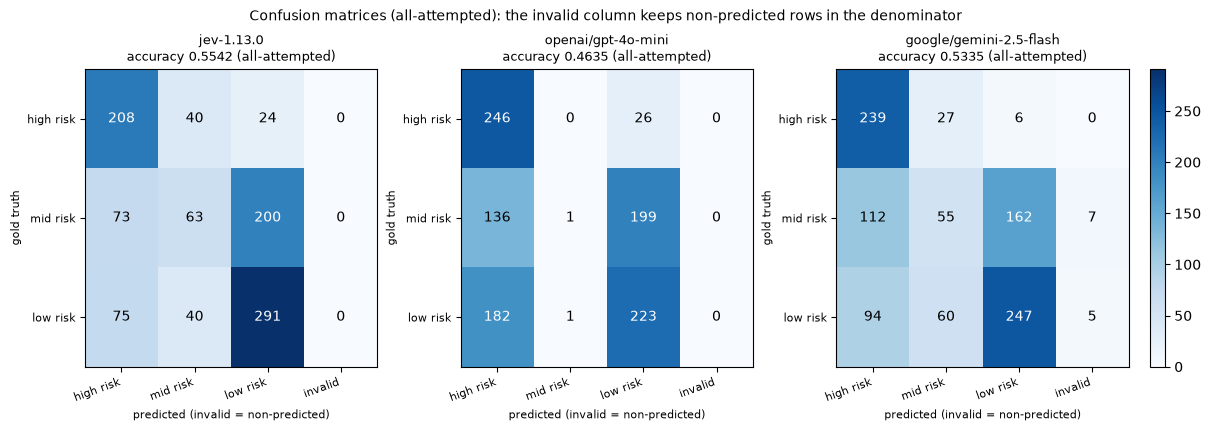

In [5]:
# Deterministic figures reuse the *report's* numbers (never recomputed here),
# so a chart cannot disagree with a table. This notebook renders them inline
# only; it never writes into docs/figures/ (the committed PNGs are produced by
# the offline `jev-benchmark figures` command).
artifacts = report_mod.load_run_artifacts(PUBLISHED)
report = report_mod.build_report(artifacts, dataset)
figures_mod.confusion_figure(report)
print(
    "inline confusion heatmaps rendered "
    "(committed PNG: docs/figures/confusion-matrices.png)"
)


## Headline metrics

**All-attempted** (primary, conservative) scores every attempted row:
accuracy = correct/attempted, macro-F1 averages the three published-class F1
values, balanced accuracy averages the three class recalls, and invalid
outcomes count as incorrect. **Success-only** is the secondary view on valid
outputs, always shown with its narrower coverage. Zero-division convention: a
class precision with no predicted positives, or a recall with no support, is
defined as 0 and stated; no such case occurs in this run.

In [6]:
head_rows = []
for model in spec.MODEL_IDS:
    aa = metrics.all_attempted_metrics(cases, model)
    so = metrics.success_only_metrics(cases, model)
    head_rows.append({
        "provider": model,
        "accuracy (all-att.)": round(aa["accuracy"], 4),
        "macro-F1 (all-att.)": round(aa["macro_f1"], 4),
        "balanced acc. (all-att.)": round(aa["balanced_accuracy"], 4),
        "high-risk recall (all-att.)": round(aa["high_risk_recall"], 4),
        "coverage": f"{so['predicted']}/{so['attempted']}",
        "accuracy (succ-only)": round(so["accuracy"], 4),
        "macro-F1 (succ-only)": round(so["macro_f1"], 4),
    })
headline_df = pd.DataFrame(head_rows).set_index("provider")
display(headline_df)

# Independent accuracy recount from raw records only.
for model in spec.MODEL_IDS:
    sub = raw[raw["model"] == model]
    independent = float((sub["final"] == sub["gold"]).mean())
    package = metrics.all_attempted_metrics(cases, model)["accuracy"]
    assert abs(independent - package) < 1e-12, f"accuracy mismatch for {model}"
    assert metrics.all_attempted_metrics(cases, model)["zero_division_notes"] == []
print("accuracy values match an independent pandas recount for all three providers")

,accuracy (all-att.),macro-F1 (all-att.),balanced acc. (all-att.),high-risk recall (all-att.),coverage,accuracy (succ-only),macro-F1 (succ-only)
provider,,,,,,,
jev-1.13.0,0.5542,0.5191,0.5563,0.7647,1014/1014,0.5542,0.5191
openai/gpt-4o-mini,0.4635,0.3722,0.4855,0.9044,1014/1014,0.4635,0.3722
google/gemini-2.5-flash,0.5335,0.4995,0.5502,0.8787,1002/1014,0.5399,0.5019


accuracy values match an independent pandas recount for all three providers


## Per-class precision / recall / F1 (all-attempted)

`support` is the gold row count; `predicted` is the column count. The
high-risk row is the safety-relevant direction to read carefully, but this is
still only label replication, not clinical sensitivity.

In [7]:
class_rows = []
for model in spec.MODEL_IDS:
    aa = metrics.all_attempted_metrics(cases, model)
    for label in spec.RISK_LABELS:
        cls = aa["classes"][label]
        class_rows.append({
            "provider": model, "class": label,
            "precision": round(cls["precision"], 4),
            "recall": round(cls["recall"], 4),
            "f1": round(cls["f1"], 4),
            "predicted": cls["predicted"], "support": cls["support"],
        })
display(pd.DataFrame(class_rows))

,provider,class,precision,recall,f1,predicted,support
0,jev-1.13.0,high risk,0.5843,0.7647,0.6624,356,272
1,jev-1.13.0,mid risk,0.4406,0.1875,0.2630,143,336
2,jev-1.13.0,low risk,0.5650,0.7167,0.6319,515,406
3,openai/gpt-4o-mini,high risk,0.4362,0.9044,0.5885,564,272
4,openai/gpt-4o-mini,mid risk,0.5000,0.0030,0.0059,2,336
5,openai/gpt-4o-mini,low risk,0.4978,0.5493,0.5222,448,406
6,google/gemini-2.5-flash,high risk,0.5371,0.8787,0.6667,445,272
7,google/gemini-2.5-flash,mid risk,0.3873,0.1637,0.2301,142,336
8,google/gemini-2.5-flash,low risk,0.5952,0.6084,0.6017,415,406


## Latency: per-call vs whole-row workflow

Two scopes are never mixed: **api-attempt** covers each finished API call
(including completed failed/retried attempts), **workflow** covers a full
row-provider two-stage workflow (one or two calls). p50/p95 carry their sample
counts; retries and failures are broken out separately. The total figure is the
run's cumulative active dispatch time (client-observed monotonic clock; idle
time is not counted).

,api p50 (s),api p95 (s),api n,wf p50 (s),wf p95 (s),wf n,retried,failed
provider,,,,,,,,
jev-1.13.0,0.167,0.623,1673,0.316,1.072,1014,1,1
openai/gpt-4o-mini,1.426,2.300,1464,1.991,3.895,1014,0,0
google/gemini-2.5-flash,1.253,3.728,1575,2.196,6.649,1014,0,12


Jev retry detail: one stage-1 attempt timed out after 31.5s (client timeout 10s); its reservation stayed 'unknown' and the retry succeeded
Gemini failure detail: 12 invalid-JSON parse attempts, p50 1.36s, max 1.89s
Total cumulative dispatch time: 5396.4s (cumulative active dispatch; monotonic client clock)


inline latency distributions rendered (committed PNG: docs/figures/latency-distributions.png)


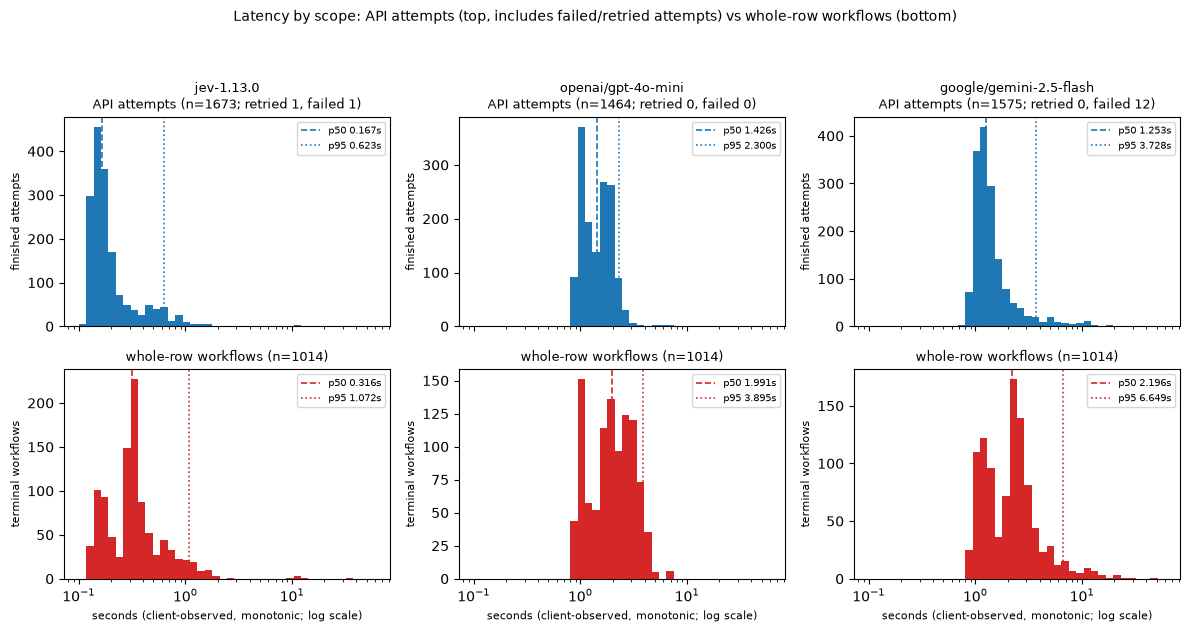

In [8]:
lat_rows = []
for model in spec.MODEL_IDS:
    lat = metrics.latency_summary(cases, model)
    lat_rows.append({
        "provider": model,
        "api p50 (s)": round(lat["api_attempt"]["p50"], 3),
        "api p95 (s)": round(lat["api_attempt"]["p95"], 3),
        "api n": lat["api_attempt"]["count"],
        "wf p50 (s)": round(lat["workflow"]["p50"], 3),
        "wf p95 (s)": round(lat["workflow"]["p95"], 3),
        "wf n": lat["workflow"]["count"],
        "retried": lat["retried_attempts"],
        "failed": lat["failed_attempts"],
    })
latency_df = pd.DataFrame(lat_rows).set_index("provider")
display(latency_df)

jev_lat = metrics.latency_summary(cases, "jev-1.13.0")
gem_lat = metrics.latency_summary(cases, "google/gemini-2.5-flash")
jev_failed = jev_lat['failed_attempt_latency']['max']
print(
    f"Jev retry detail: one stage-1 attempt timed out after "
    f"{jev_failed:.1f}s "
    "(client timeout 10s); its reservation stayed 'unknown' and the retry succeeded"
)
gem_failed = gem_lat['failed_attempt_latency']
print(
    f"Gemini failure detail: {gem_lat['failed_attempts']} invalid-JSON parse "
    f"attempts, p50 {gem_failed['p50']:.2f}s, max {gem_failed['max']:.2f}s"
)
print(f"Total cumulative dispatch time: {run_state['total_run_seconds']:.1f}s "
      "(cumulative active dispatch; monotonic client clock)")

# Deterministic inline figure: the same latency-distribution chart the
# committed docs/figures/latency-distributions.png carries, drawn from the
# report's numbers. Rendered inline only; nothing is written to disk.
figures_mod.latency_figure(report, cases)
print(
    "inline latency distributions rendered "
    "(committed PNG: docs/figures/latency-distributions.png)"
)


## Cost: billed vs estimated vs unknown (never conflated)

* **OpenRouter billed**: actual `usage.cost` values the provider reported.
* **Jev rate-estimated**: token counts times the published $0.042/M rate; Jev
  exposes no billed-dollar field, so this is an estimate, not a bill.
* **Unknown reserved**: conservative retained reservations for attempts whose
  billable amount is unknown (here: the one timed-out Jev attempt) - never
  assumed free.

`full-run marginal` replays only this run's per-attempt settlements;
`shared cumulative` is the committed snapshot of the cross-phase $20 software
guard (a conservative local guard, not a vendor-enforced cap).

,OpenRouter billed ($),Jev est. ($),unknown reserved ($),input tokens,output tokens,attempts missing usage
provider,,,,,,
jev-1.13.0,0.000000,0.029806,0.005,656162,53504,1
openai/gpt-4o-mini,0.081490,0.000000,0.000,391008,38064,0
google/gemini-2.5-flash,0.266026,0.000000,0.000,373385,61604,0


full-run marginal spend : $0.347515 billed + $0.029806 Jev-estimated + $0.005000 unknown = $0.382321
shared cumulative guard : $0.490581 of $20.00 (seed $0.100000 + billed $0.349351 + Jev est $0.029914 + unknown $0.011316)
pre-repair planning preflight (outside the ledger, disclosed once): $0.0004434 OpenRouter billed + $0.0000797 Jev rate-estimated
inline cost-by-basis chart rendered (committed PNG: docs/figures/cost-by-basis.png)


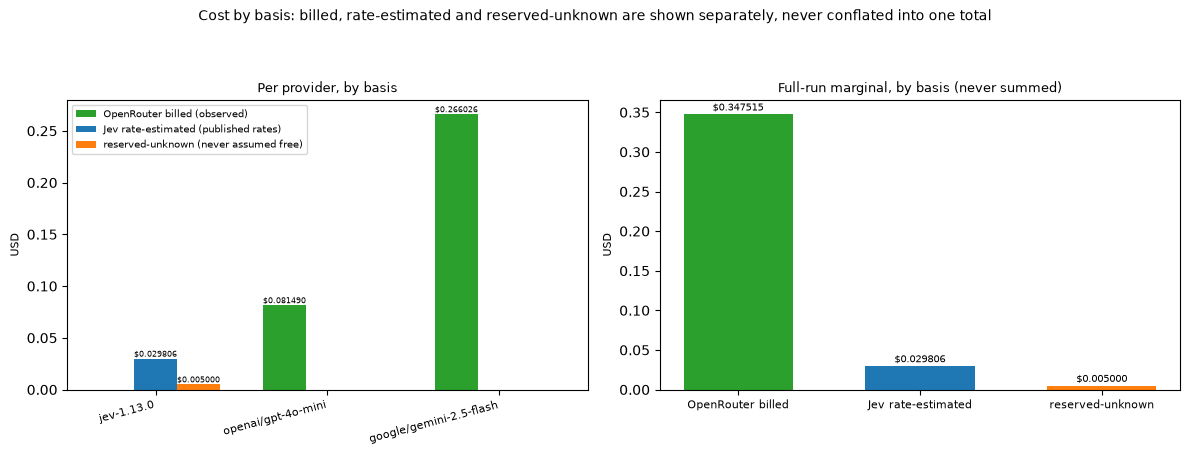

In [9]:
cost_rows = []
for model in spec.MODEL_IDS:
    c = metrics.cost_summary(cases, model)
    cost_rows.append({
        "provider": model,
        "OpenRouter billed ($)": round(c["billed_openrouter"], 6),
        "Jev est. ($)": round(c["estimated_jev"], 6),
        "unknown reserved ($)": round(c["reserved_unknown"], 6),
        "input tokens": c["input_tokens"],
        "output tokens": c["output_tokens"],
        "attempts missing usage": c["attempts_missing_usage"],
    })
cost_df = pd.DataFrame(cost_rows).set_index("provider")
display(cost_df)

marginal_billed = sum(metrics.cost_summary(cases, m)["billed_openrouter"] for m in spec.MODEL_IDS)
marginal_est = sum(metrics.cost_summary(cases, m)["estimated_jev"] for m in spec.MODEL_IDS)
marginal_unknown = sum(metrics.cost_summary(cases, m)["reserved_unknown"] for m in spec.MODEL_IDS)
print(
    f"full-run marginal spend : ${marginal_billed:.6f} billed + "
    f"${marginal_est:.6f} Jev-estimated + ${marginal_unknown:.6f} unknown = "
    f"${marginal_billed + marginal_est + marginal_unknown:.6f}"
)
print(
    f"shared cumulative guard : ${shared_budget['exposure']:.6f} of "
    f"${shared_budget['cap']:.2f} (seed ${shared_budget['planning_seed']:.6f} + "
    f"billed ${shared_budget['billed_openrouter']:.6f} + "
    f"Jev est ${shared_budget['estimated_jev']:.6f} + "
    f"unknown ${shared_budget['reserved_unknown']:.6f})"
)

# The pre-repair planning preflight (committed for cost reconciliation) predates
# the durable shared ledger; it is neither lost nor double-counted.
pre_preflight = json.loads((PUBLISHED / "preflight-20261005T182244Z.json").read_text())
rate = shared_budget["pricing"]["jev_input_rate"]
tot = {}
for p in pre_preflight["providers"]:
    u = p["usage_totals"]
    billed = u["cost"] or 0.0
    jev_est = ((u["input_tokens"] or 0) + (u["output_tokens"] or 0)) * rate
    tot[p["requested_model"]] = {"billed": billed, "jev_est": jev_est}
pf_billed = sum(v["billed"] for v in tot.values())
pf_jev = sum(v["jev_est"] for v in tot.values())
print(f"pre-repair planning preflight (outside the ledger, disclosed once): "
      f"${pf_billed:.7f} OpenRouter billed + ${pf_jev:.7f} Jev rate-estimated")

# Same cost-by-basis chart as the committed docs/figures/cost-by-basis.png:
# billed, rate-estimated and reserved-unknown shown separately, never summed.
figures_mod.cost_figure(report)
print(
    "inline cost-by-basis chart rendered "
    "(committed PNG: docs/figures/cost-by-basis.png)"
)


## Paired uncertainty

All three providers scored the same frozen rows, so comparisons are paired.
The 95% intervals are a deterministic (seeded) nonparametric row bootstrap over
each provider's 1,014 attempted rows; the McNemar tests are exact two-sided
binomial tests on the discordant pairs, with **no multiple-comparison
correction** applied. Overlapping intervals and uncorrected p-values are
descriptive, not proof of superiority.

In [10]:
unc_rows = []
for model in spec.MODEL_IDS:
    u = metrics.bootstrap_intervals(cases, model, n_boot=10_000, seed=20261006)
    unc_rows.append({
        "provider": model,
        "accuracy": f"[{u['accuracy']['lo']:.4f}, {u['accuracy']['hi']:.4f}]",
        "macro-F1": f"[{u['macro_f1']['lo']:.4f}, {u['macro_f1']['hi']:.4f}]",
        "balanced acc.": (
            f"[{u['balanced_accuracy']['lo']:.4f}, {u['balanced_accuracy']['hi']:.4f}]"
        ),
        "high-risk recall": (
            f"[{u['high_risk_recall']['lo']:.4f}, {u['high_risk_recall']['hi']:.4f}]"
        ),
    })
display(pd.DataFrame(unc_rows).set_index("provider"))

mc_rows = []
for a, b in combinations(spec.MODEL_IDS, 2):
    res = metrics.mcnemar_exact(
        metrics.paired_correctness(cases, a), metrics.paired_correctness(cases, b))
    mc_rows.append({"A": a, "B": b, "A-only correct": res["a_only_correct"],
                    "B-only correct": res["b_only_correct"],
                    "both correct": res["both_correct"], "both wrong": res["both_wrong"],
                    "exact p": f"{res['p_value']:.2e}"})
display(pd.DataFrame(mc_rows))

,accuracy,macro-F1,balanced acc.,high-risk recall
provider,,,,
jev-1.13.0,"[0.5237, 0.5858]","[0.4903, 0.5485]","[0.5298, 0.5824]","[0.7128, 0.8145]"
openai/gpt-4o-mini,"[0.4329, 0.4951]","[0.3505, 0.3936]","[0.4649, 0.5050]","[0.8677, 0.9377]"
google/gemini-2.5-flash,"[0.5039, 0.5641]","[0.4712, 0.5282]","[0.5259, 0.5746]","[0.8379, 0.9155]"


,A,B,A-only correct,B-only correct,both correct,both wrong,exact p
0,jev-1.13.0,openai/gpt-4o-mini,196,104,366,348,1.20e-07
1,jev-1.13.0,google/gemini-2.5-flash,140,119,422,333,2.14e-01
2,openai/gpt-4o-mini,google/gemini-2.5-flash,63,134,407,410,4.65e-07


## Duplicate-feature sensitivity

The primary population is always the full 1,014-row frozen set. Two sensitivity
views re-weight the same predictions: (1) the **452 distinct complete rows**
(first occurrence of each identical features+label row), and (2) the **381
distinct feature vectors with unambiguous labels** (35 conflicting-label groups,
215 rows, excluded because their gold label is ambiguous). These views change
denominators; they do not replace the published population.

In [11]:
dedup = metrics.dedup_row_indices(dataset.records)
sens_rows = []
for model in spec.MODEL_IDS:
    primary = metrics.all_attempted_metrics(cases, model)
    complete_view = metrics.all_attempted_metrics_for_rows(
        cases, model, dedup["distinct_complete_row_indices"])
    vector_view = metrics.all_attempted_metrics_for_rows(
        cases, model, dedup["nonconflicting_feature_vector_indices"])
    sens_rows.append({
        "provider": model,
        "accuracy (1014 rows)": round(primary["accuracy"], 4),
        "accuracy (452 rows)": round(complete_view["accuracy"], 4),
        "accuracy (381 vectors)": round(vector_view["accuracy"], 4),
        "macro-F1 (1014)": round(primary["macro_f1"], 4),
        "macro-F1 (452)": round(complete_view["macro_f1"], 4),
        "macro-F1 (381)": round(vector_view["macro_f1"], 4),
        "high-risk recall (1014)": round(primary["high_risk_recall"], 4),
        "high-risk recall (452)": round(complete_view["high_risk_recall"], 4),
        "high-risk recall (381)": round(vector_view["high_risk_recall"], 4),
    })
display(pd.DataFrame(sens_rows).set_index("provider"))
print(
    f"35 conflicting-label groups ({dedup['conflicting_rows']} rows) are excluded "
    f"from the feature-vector view; 416 distinct vectors - 35 = "
    f"{dedup['nonconflicting_feature_vectors']} rows there"
)

,accuracy (1014 rows),accuracy (452 rows),accuracy (381 vectors),macro-F1 (1014),macro-F1 (452),macro-F1 (381),high-risk recall (1014),high-risk recall (452),high-risk recall (381)
provider,,,,,,,,,
jev-1.13.0,0.5542,0.5907,0.6220,0.5191,0.5212,0.5460,0.7647,0.6696,0.6832
openai/gpt-4o-mini,0.4635,0.4912,0.5118,0.3722,0.3694,0.3782,0.9044,0.8393,0.8416
google/gemini-2.5-flash,0.5335,0.5708,0.5984,0.4995,0.5105,0.5326,0.8787,0.8393,0.8416


35 conflicting-label groups (215 rows) are excluded from the feature-vector view; 416 distinct vectors - 35 = 381 rows there


## Exploratory: stage-1 self-reported probabilities (not a calibration claim)

Each provider reports a stage-1 `P(high)` alongside its choice. These values are
**not validated calibrated estimates**, are not guaranteed to agree with the
provider's own recorded choice (Jev, in particular, can choose `high` while
reporting `P(high) = 0.21`), and Jev's and OpenRouter's scales are not known to
be comparable. The Brier scores below are exploratory context only and form no
part of the headline comparison. Gemini's denominator is 1,006 because its 8
rows that failed stage-1 parsing never produced a probability.

In [12]:
cal = report_mod.exploratory_calibration(stage_entries, cases)
print(cal["qualification"])
cal_rows = []
for model, values in cal["providers"].items():
    cal_rows.append({
        "provider": model,
        "n (stage-1 with P(high))": values["n"],
        "Brier": round(values["brier"], 4),
        "mean P(high) | gold high": round(values["mean_p_high_when_gold_high"], 4),
        "mean P(high) | gold other": round(values["mean_p_high_when_gold_other"], 4),
    })
display(pd.DataFrame(cal_rows).set_index("provider"))

Exploratory only: providers' self-reported probabilities are not validated calibrated estimates, are not guaranteed to be argmax-consistent with their recorded choices, and Jev's and OpenRouter's probability scales are not known to be comparable. Brier = mean((reported P(high) - gold high-vs-other)^2) over stage-1 rows with reported probabilities.


,n (stage-1 with P(high)),Brier,mean P(high) | gold high,mean P(high) | gold other
provider,,,,
jev-1.13.0,1014,0.1317,0.6778,0.2385
openai/gpt-4o-mini,1014,0.2600,0.7833,0.4497
google/gemini-2.5-flash,1006,0.2167,0.8414,0.3023


## Two-stage gating re-verified from saved data

From the committed stage journal alone: every stage-2 dispatch followed that
provider's **own** stage-1 `other` answer (never a `high`, never the gold label
or another provider's answer), and the journal reconciles exactly with the
successful attempts recorded in the case files.

In [13]:
gating = report_mod.verify_stage_journal(stage_entries, cases)
print(f"journaled successful stages : {gating['journaled_stage_entries']}")
print(
    f"keys with a stage 2         : {gating['keys_with_stage2']} "
    "(all preceded by this provider's own 'other')"
)
print(f"stage-1 'high' (no stage 2) : {gating['stage1_high_keys']}")
assert gating["gating_consistent"] is True

stage_counts = {}
for model in spec.MODEL_IDS:
    subset = [c for c in cases if c.requested_model == model]
    stage_counts[model] = {
        "single-stage cases": sum(1 for c in subset if c.stage_count == 1),
        "two-stage cases": sum(1 for c in subset if c.stage_count == 2),
    }
display(pd.DataFrame(stage_counts).T)

print("all reconciliation checks passed: this notebook's tables and the README derive "
      "from the same committed artifacts of the same completed run "
      f"({run_state['run_id']})")

journaled successful stages : 4699
keys with a stage 2         : 1665 (all preceded by this provider's own 'other')
stage-1 'high' (no stage 2) : 1365


,single-stage cases,two-stage cases
jev-1.13.0,356,658
openai/gpt-4o-mini,564,450
google/gemini-2.5-flash,453,561


all reconciliation checks passed: this notebook's tables and the README derive from the same committed artifacts of the same completed run (run-20261006T142452Z)
